## 1. Загрузка данных

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", font_scale=1.02)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 105

csv_path = Path("train.csv")
if not csv_path.is_file():
    raise FileNotFoundError(
        "Не найден train.csv. Поместите файл в рабочую папку рядом с hw_4.ipynb. "
        f"Текущая рабочая папка: {Path.cwd()}"
    )

df = pd.read_csv(csv_path)
required = {"PassengerId", "Survived", "Pclass", "Age", "Sex", "Parch"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"В данных отсутствуют обязательные столбцы: {sorted(missing)}")

print(f"Размер датасета: {df.shape[0]} строк × {df.shape[1]} столбцов")
print(f"Число пропусков Age: {df['Age'].isna().sum()}")
display(df.head())

Размер датасета: 891 строк × 12 столбцов
Число пропусков Age: 177


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Распределение признаков `Survived`, `Pclass`, `Age`, `Sex`, `Parch`


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


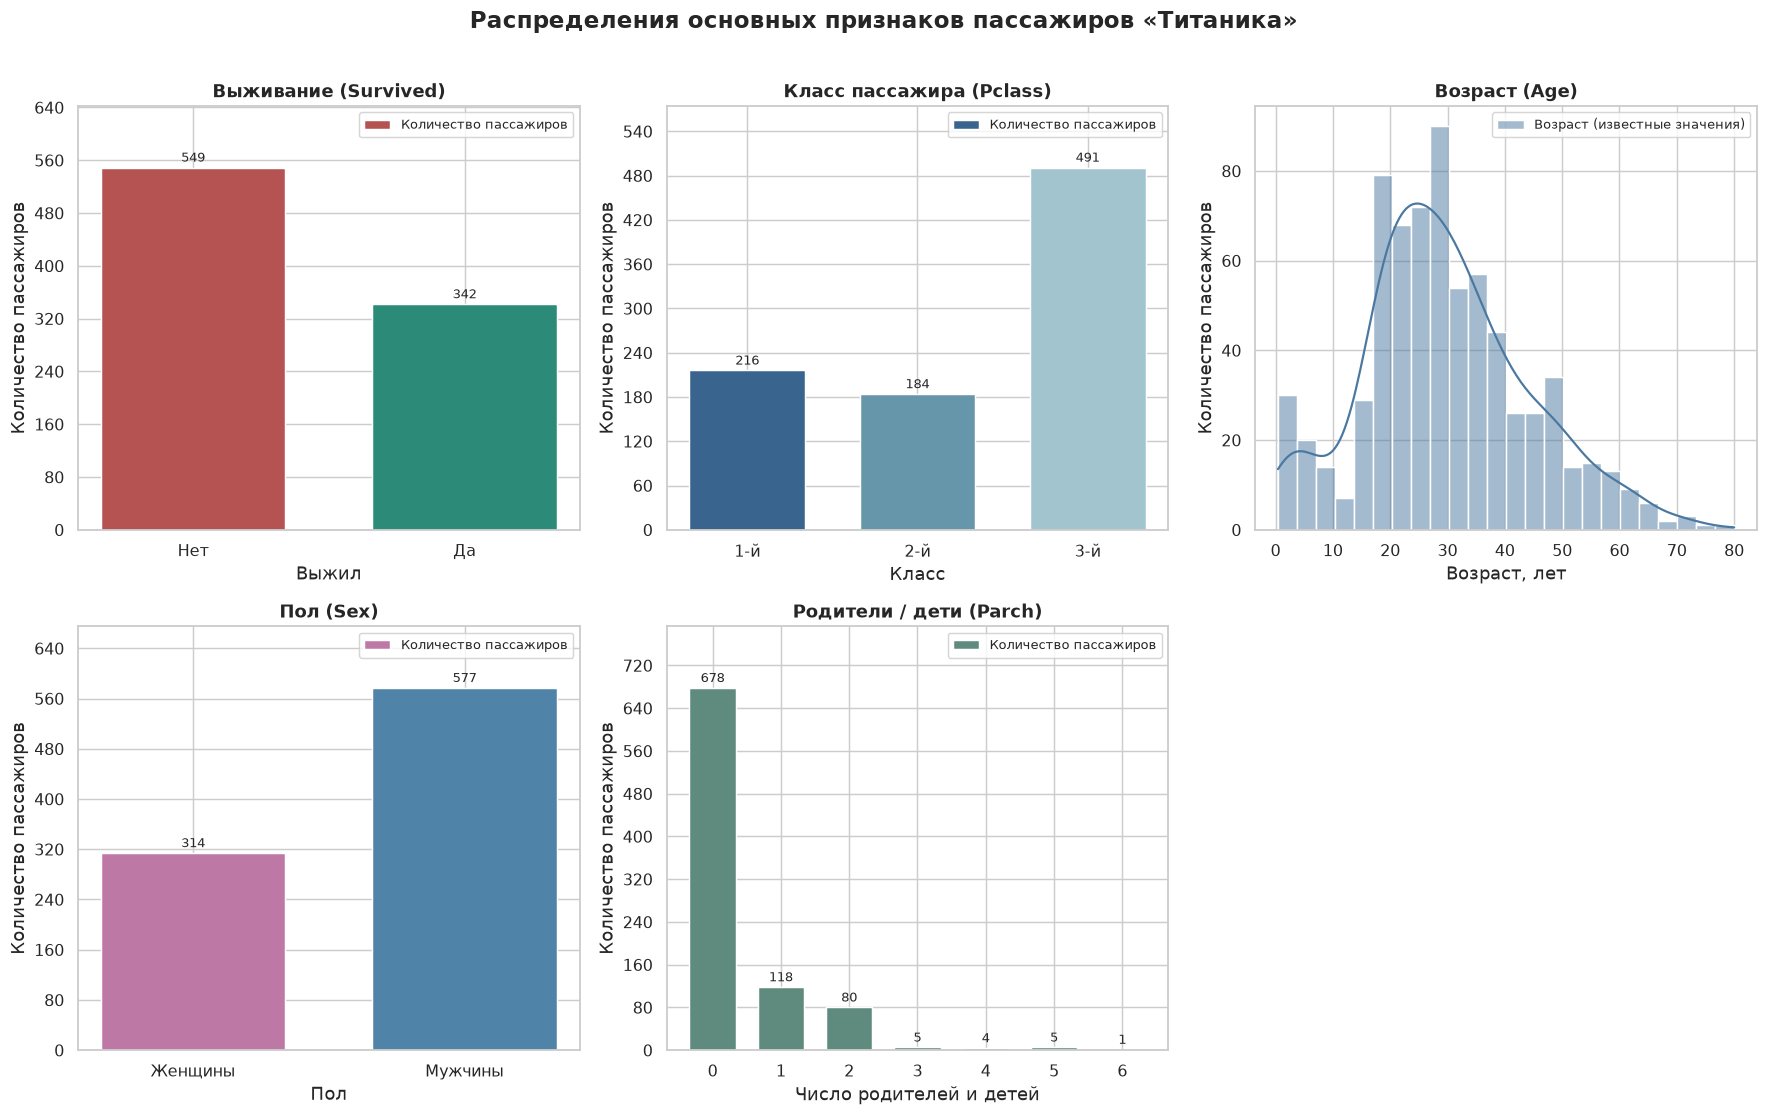

Для Age показаны только пассажиры с известным возрастом; остальные признаки включают всю выборку.


In [2]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
fig.suptitle("Распределения основных признаков пассажиров «Титаника»", fontsize=16, fontweight="bold", y=1.01)


def plot_category(ax, column, title, xlabel, categories, labels, colors):
    counts = df[column].value_counts().reindex(categories, fill_value=0)
    positions = np.arange(len(categories))
    bars = ax.bar(positions, counts.to_numpy(), color=colors, width=0.68, edgecolor="white")
    ax.set_xticks(positions, [labels.get(value, str(value)) for value in categories])
    ax.set_title(title, fontweight="semibold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Количество пассажиров")
    ax.set_ylim(0, max(counts.max() * 1.17, 1))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    for rect in bars:
        ax.annotate(f"{int(rect.get_height())}",
                    (rect.get_x() + rect.get_width()/2, rect.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.legend(handles=[Patch(facecolor=colors[0], label="Количество пассажиров")],
              fontsize=9, frameon=True, loc="upper right")

plot_category(axes[0, 0], "Survived", "Выживание (Survived)", "Выжил", [0, 1],
              {0: "Нет", 1: "Да"}, ["#B55252", "#2B8A78"])
plot_category(axes[0, 1], "Pclass", "Класс пассажира (Pclass)", "Класс", [1, 2, 3],
              {1: "1-й", 2: "2-й", 3: "3-й"}, ["#38648E", "#6596A9", "#A1C4CF"])

known_age = df["Age"].dropna()
sns.histplot(known_age, bins=24, kde=True, color="#4A78A0", edgecolor="white",
             ax=axes[0, 2], label="Возраст (известные значения)")
axes[0, 2].set_title("Возраст (Age)", fontweight="semibold")
axes[0, 2].set_xlabel("Возраст, лет")
axes[0, 2].set_ylabel("Количество пассажиров")
axes[0, 2].legend(fontsize=9, loc="upper right")

plot_category(axes[1, 0], "Sex", "Пол (Sex)", "Пол", ["female", "male"],
              {"female": "Женщины", "male": "Мужчины"}, ["#BE78A5", "#4F83A8"])
parch_values = sorted(df["Parch"].dropna().unique())
plot_category(axes[1, 1], "Parch", "Родители / дети (Parch)",
              "Число родителей и детей", parch_values, {}, ["#5E8B7E"] * len(parch_values))
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

print("Для Age показаны только пассажиры с известным возрастом; остальные признаки включают всю выборку.")

## 3. Boxplot для столбца `Age`



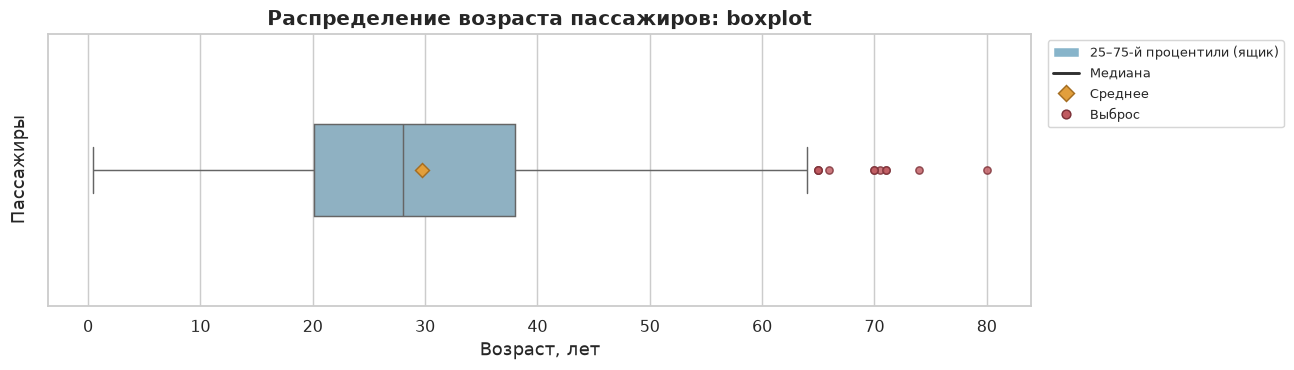

In [3]:
age = df["Age"].dropna()
q1, median, q3 = age.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
outliers = age[(age < lower_limit) | (age > upper_limit)]

fig, ax = plt.subplots(figsize=(12.5, 3.7))
sns.boxplot(x=age, ax=ax, color="#87B4CA", width=0.34,
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": "#E29F3C",
                                       "markeredgecolor": "#A46D21", "markersize": 7},
            flierprops={"marker": "o", "markersize": 5,
                        "markerfacecolor": "#C05A60", "markeredgecolor": "#7C3138", "alpha": 0.82})
ax.set_title("Распределение возраста пассажиров: boxplot", fontsize=14, fontweight="bold")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Пассажиры")
ax.legend(handles=[Patch(facecolor="#87B4CA", label="25–75-й процентили (ящик)"),
                   Line2D([0], [0], color="#303030", linewidth=2, label="Медиана"),
                   Line2D([0], [0], marker="D", color="w", markerfacecolor="#E29F3C",
                          markeredgecolor="#A46D21", markersize=8, label="Среднее"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor="#C05A60",
                          markeredgecolor="#7C3138", markersize=6, label="Выброс")],
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

## 4. Интерпретация boxplot



In [4]:
nonoutlier = age[(age >= lower_limit) & (age <= upper_limit)]
summary = f"""**Интерпретация распределения возраста:**

- Из {len(df)} пассажиров возраст известен у **{len(age)}**, отсутствует у **{df['Age'].isna().sum()}**.
- **Медиана — {median:.1f} года**, а **средний возраст — {age.mean():.1f} года**. Среднее немного выше медианы, что указывает на небольшую правостороннюю асимметрию распределения.
- Первый квартиль **Q1 = {q1:.3f}**, третий квартиль **Q3 = {q3:.1f}**. Следовательно, центральные 50% известных возрастов расположены приблизительно **от {q1:.1f} до {q3:.1f} лет**.
- Межквартильный размах **IQR = {iqr:.3f} года**. Верхняя граница правила 1,5×IQR — **{upper_limit:.2f} года**, нижняя — **{lower_limit:.2f} года**.
- На boxplot **{len(outliers)} потенциальных выбросов**: это наблюдения с возрастом старше {upper_limit:.1f} года. Верхний «ус» достигает примерно **{nonoutlier.max():g} лет**.
- Минимальный известный возраст — **{age.min():g} года**, максимальный — **{age.max():g} лет**. Это реальные значения датасета; «усы» boxplot не обязательно доходят до абсолютных экстремумов.

**Вывод:** основная масса пассажиров с известным возрастом — молодые и люди среднего возраста; присутствует небольшое число относительно пожилых пассажиров. Пропуски в `Age` нужно учитывать при интерпретации результатов.
"""
display(Markdown(summary))

**Интерпретация распределения возраста:**

- Из 891 пассажиров возраст известен у **714**, отсутствует у **177**.
- **Медиана — 28.0 года**, а **средний возраст — 29.7 года**. Среднее немного выше медианы, что указывает на небольшую правостороннюю асимметрию распределения.
- Первый квартиль **Q1 = 20.125**, третий квартиль **Q3 = 38.0**. Следовательно, центральные 50% известных возрастов расположены приблизительно **от 20.1 до 38.0 лет**.
- Межквартильный размах **IQR = 17.875 года**. Верхняя граница правила 1,5×IQR — **64.81 года**, нижняя — **-6.69 года**.
- На boxplot **11 потенциальных выбросов**: это наблюдения с возрастом старше 64.8 года. Верхний «ус» достигает примерно **64 лет**.
- Минимальный известный возраст — **0.42 года**, максимальный — **80 лет**. Это реальные значения датасета; «усы» boxplot не обязательно доходят до абсолютных экстремумов.

**Вывод:** основная масса пассажиров с известным возрастом — молодые и люди среднего возраста; присутствует небольшое число относительно пожилых пассажиров. Пропуски в `Age` нужно учитывать при интерпретации результатов.


## 5. Круговые диаграммы (pie charts) для `Survived` и `Pclass`



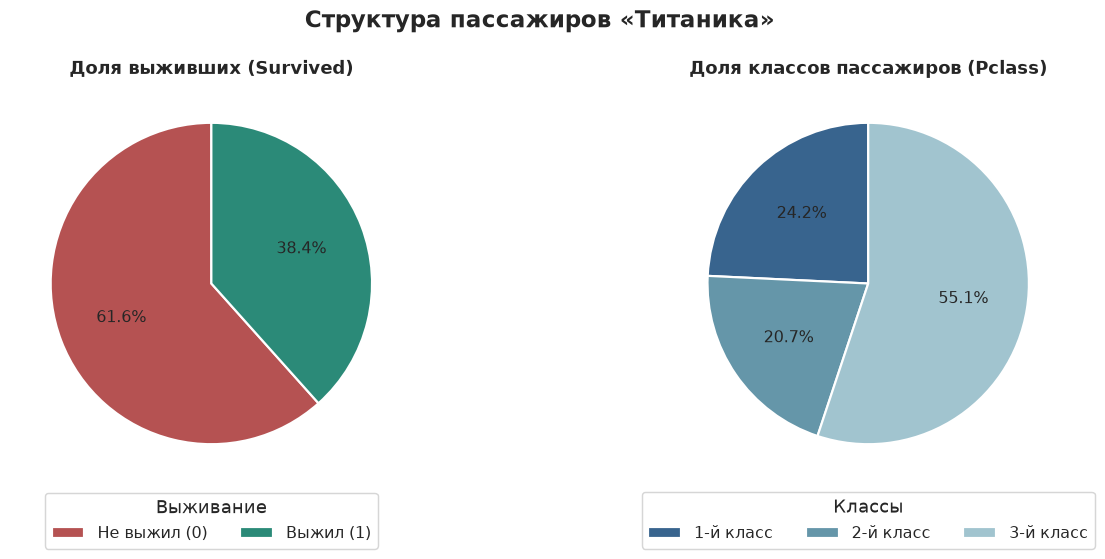

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle("Структура пассажиров «Титаника»", fontsize=16, fontweight="bold")

survived_counts = df["Survived"].value_counts().reindex([0, 1], fill_value=0)
wedges1, _, _ = axes[0].pie(survived_counts, labels=None, autopct="%1.1f%%",
                             startangle=90, colors=["#B55252", "#2B8A78"],
                             wedgeprops={"edgecolor": "white", "linewidth": 1.5},
                             textprops={"fontsize": 11})
axes[0].set_title("Доля выживших (Survived)", fontweight="semibold")
axes[0].legend(wedges1, ["Не выжил (0)", "Выжил (1)"], title="Выживание",
               loc="lower center", bbox_to_anchor=(0.5, -0.18), ncol=2)

class_counts = df["Pclass"].value_counts().reindex([1, 2, 3], fill_value=0)
wedges2, _, _ = axes[1].pie(class_counts, labels=None, autopct="%1.1f%%",
                             startangle=90, colors=["#38648E", "#6596A9", "#A1C4CF"],
                             wedgeprops={"edgecolor": "white", "linewidth": 1.5},
                             textprops={"fontsize": 11})
axes[1].set_title("Доля классов пассажиров (Pclass)", fontweight="semibold")
axes[1].legend(wedges2, ["1-й класс", "2-й класс", "3-й класс"], title="Классы",
               loc="lower center", bbox_to_anchor=(0.5, -0.18), ncol=3)

plt.tight_layout()
plt.show()

## 6. Pairplot по всем числовым переменным


Все числовые признаки: PassengerId, Survived, Pclass, Age, SibSp, Parch, Fare


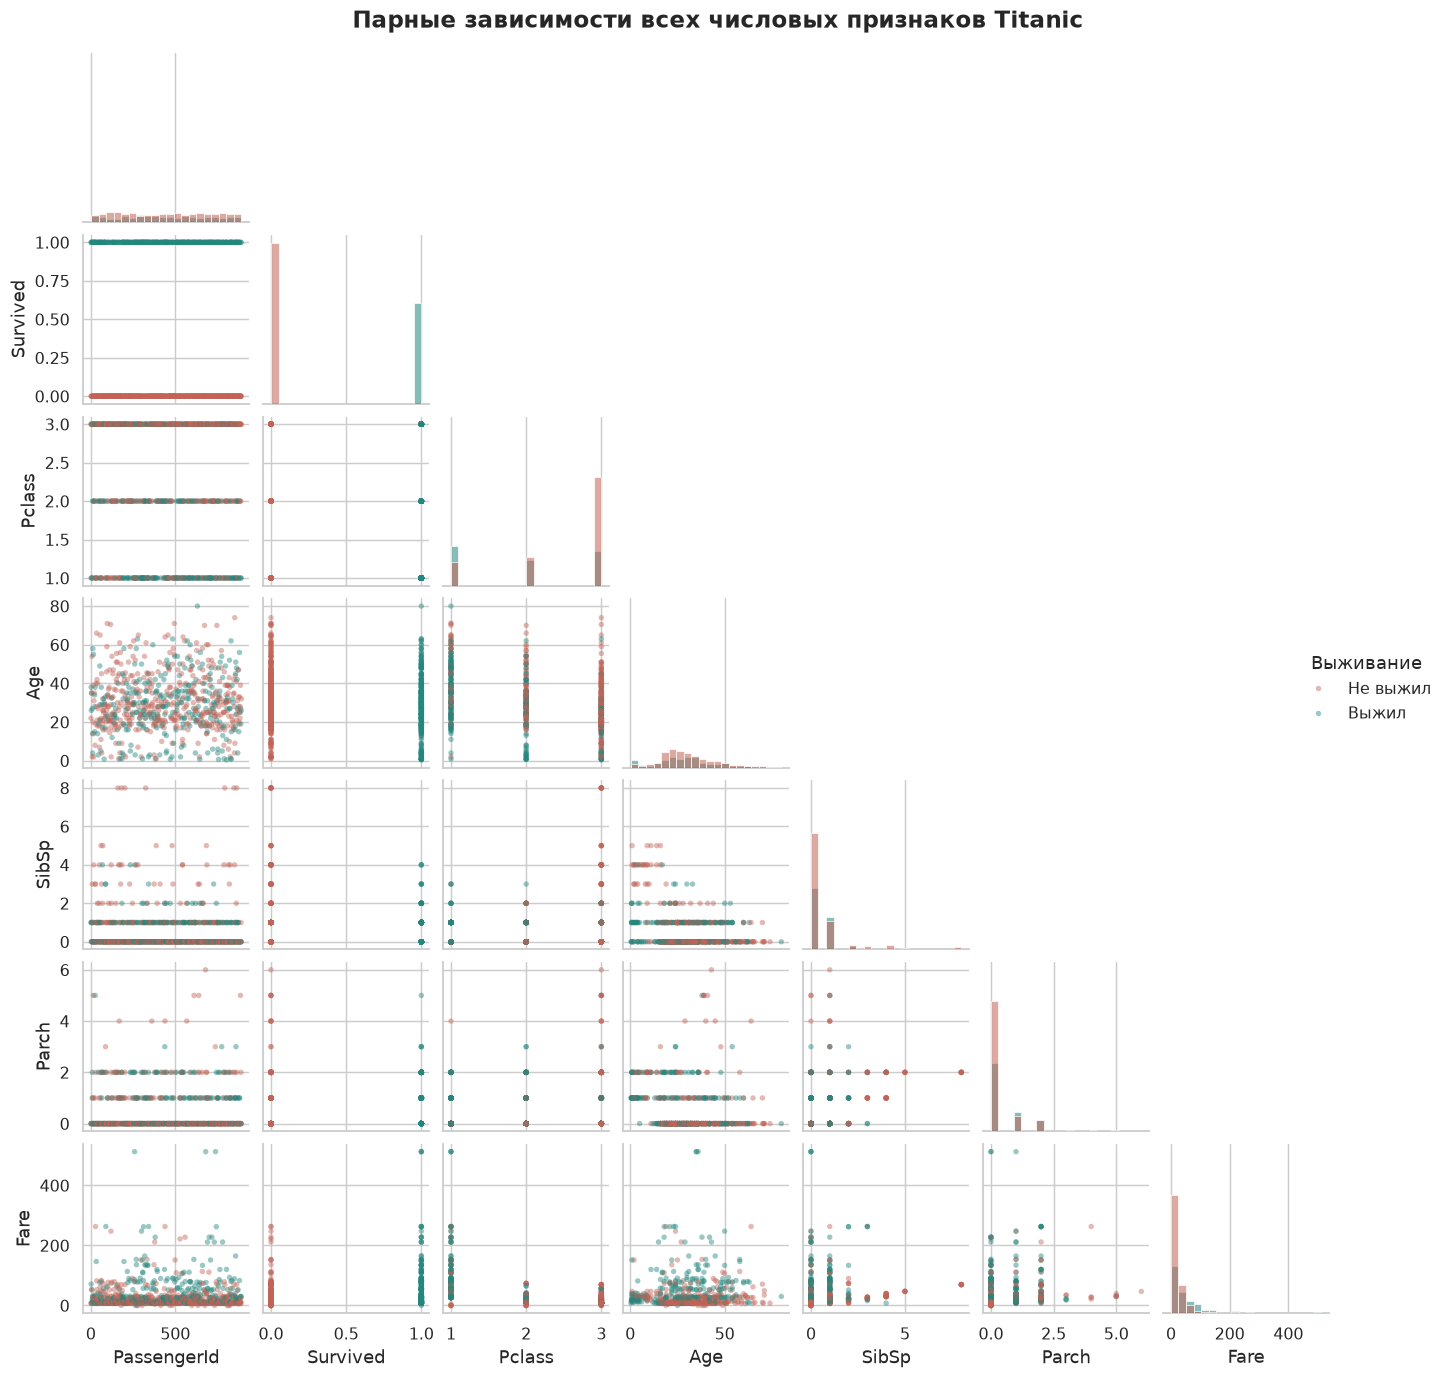

In [6]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
print("Все числовые признаки:", ", ".join(numeric_columns))

pair = sns.pairplot(
    data=df,
    vars=numeric_columns,
    hue="Survived",
    palette={0: "#C16457", 1: "#23877E"},
    diag_kind="hist",
    corner=True,
    dropna=True,
    height=1.85,
    plot_kws={"alpha": 0.45, "s": 14, "edgecolor": "none"},
    diag_kws={"bins": 20, "alpha": 0.55},
)
pair.fig.suptitle("Парные зависимости всех числовых признаков Titanic", y=1.015,
                  fontsize=16, fontweight="bold")
if pair._legend is not None:
    pair._legend.set_title("Выживание")
    for label in pair._legend.texts:
        label.set_text({"0": "Не выжил", "1": "Выжил"}.get(label.get_text(), label.get_text()))
plt.show()

## 7. Интерактивный Sunburst: класс → пол


In [7]:
sunburst_data = (
    df.assign(
        Класс=df["Pclass"].map({1: "1-й класс", 2: "2-й класс", 3: "3-й класс"}),
        Пол=df["Sex"].map({"female": "Женщины", "male": "Мужчины"}),
    )
    .groupby(["Класс", "Пол"], as_index=False)
    .agg(Пассажиров=("PassengerId", "size"))
)

display(sunburst_data.rename(columns={"Пассажиров": "Число пассажиров"}))
class_colors = {"1-й класс": "#38648E", "2-й класс": "#6596A9", "3-й класс": "#A1C4CF"}

fig = px.sunburst(
    sunburst_data,
    path=["Класс", "Пол"],
    values="Пассажиров",
    color="Класс",
    color_discrete_map=class_colors,
    title="Число пассажиров по классу и полу — интерактивный Sunburst",
    width=950,
    height=690,
)
fig.update_traces(textinfo="label+value+percent parent", insidetextorientation="radial",
                  hovertemplate="%{label}<br>Число пассажиров: %{value}<br>Доля от родительской группы: %{percentParent:.1%}<extra></extra>")
fig.update_layout(
    margin=dict(t=85, l=30, r=190, b=30),
    font=dict(family="Arial", size=13),
    paper_bgcolor="white",
)
for j, (name, color) in enumerate(class_colors.items()):
    fig.add_annotation(x=1.05, y=0.86 - j * 0.075, xref="paper", yref="paper",
                       text=f'<span style="color:{color}">■</span> {name}',
                       showarrow=False, align="left", font=dict(size=13))
fig.add_annotation(x=1.05, y=0.96, xref="paper", yref="paper", text="<b>Легенда классов</b>",
                   showarrow=False, align="left", font=dict(size=13))
fig.show()

,Класс,Пол,Число пассажиров
0,1-й класс,Женщины,94
1,1-й класс,Мужчины,122
2,2-й класс,Женщины,76
3,2-й класс,Мужчины,108
4,3-й класс,Женщины,144
5,3-й класс,Мужчины,347
